# Supplementary Fig S3 · Index cost against the number of cells and genes

The ladders of the old Fig S1 (`_backup_2026-11-03/S1_build.ipynb`, C–D); its A (datasets) and B (build time per
dataset) are now supplementary Table S1 (`T_supplement.ipynb`).

* **A** storage, build time and peak memory against the number of cells (tonsil, subsampled).
* **B** the same against the number of genes (lymph node 5k).

**Run first:** `R0_index_cache` → `R1_index_cost` (reads `results/index_cost/builds.csv` and `ladder.csv`).
Writes `figures/figS3_scaling/panels/{A,B,legend}.{pdf,png}` and `figures/figS3_scaling/figS3_scaling.{pdf,png}`.

In [1]:
import math
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

import style as ps

FIG = "figS3_scaling"
RES = ROOT / "results" / "index_cost"
ORDER = ps.DATASET_ORDER
TC = ps.TIER_COLORS

b = pd.read_csv(RES / "builds.csv")
b["naive_build_s"] = b[["prepare_s", "layout_s", "naive_s"]].sum(axis=1)
b["key"] = pd.Categorical(b["key"], ORDER, ordered=True)
b = b.sort_values(["key", "seed"])
lad = pd.read_csv(RES / "ladder.csv")
print(sorted(set(b.tag)), sorted(set(lad.tag)))

# row 1 geometry (mm): every row-1 panel has the same height and vertical margins, so the dataset rows line up
H1, TOP, BOTTOM = 54.0, 6.5, 11.0
ROW_OFF = 0.17  # the two storage rows of a dataset
STORAGE_XLIM = (0.7, 8000.0)  # MB
W_A, W_C = 82.0, 98.0
# row 2: a title line, then three stacked axes sharing x
W_D, TITLE, H_TOP, H_BOTTOM = 88.0, 5.0, 32.0, 38.0
H2 = TITLE + 2 * H_TOP + H_BOTTOM


def box(fig, x, y, w, h):
    """Axes occupying the w x h mm box at (x, y) mm from the panel's top-left corner."""
    W, H = ps.size_mm(fig)
    return ps.axes(fig, left=x, top=y, right=W - x - w, bottom=H - y - h)


def rows(ax):
    n = len(ORDER)
    ax.set_ylim(n - 0.5, -0.5)
    ax.set_yticks(range(n))
    return n


def mean_sd(col):
    g = b.groupby("key", observed=True)[col]
    return g.mean().to_numpy(), g.std().to_numpy()


def marker(ax, x, y, tier, mk, filled=True, xerr=None, ms=3.2):
    k = TC[tier]
    ax.errorbar(x, y, xerr=xerr, fmt=mk, ms=ms, color=k, mfc=k if filled else "white", mec=k, mew=0.8,
                elinewidth=0.6, zorder=3)


def row_axis(ax):
    ax.set_yticklabels([])
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)

['method-v2'] ['method-v2']


## C–D · Ladders: storage, build time (Spindle-naive's full build, solid; what each other index adds, dashed), peak memory

figures/figS3_scaling/panels/A.pdf/.png: 88 x 107 mm, 0.0 / 0.7 MB
figures/figS3_scaling/panels/B.pdf/.png: 88 x 107 mm, 0.0 / 0.6 MB


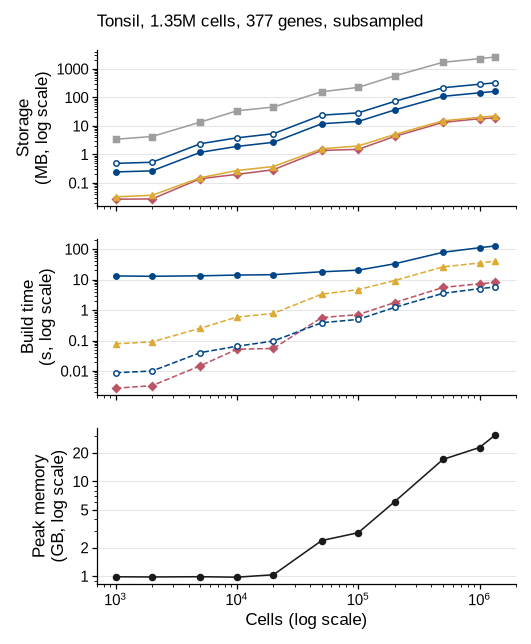

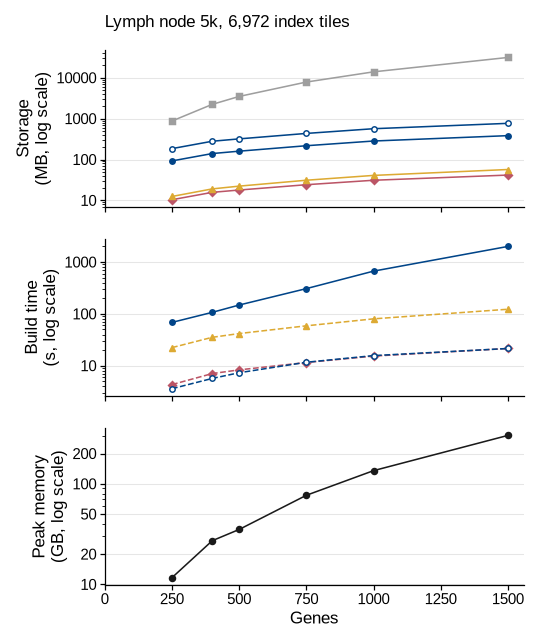

In [2]:
LEFT, RIGHT = 15.0, 2.0


def line(ax, x, y, tier, mk, filled=True, ls="-"):
    k = TC[tier]
    ax.plot(x, y, ls=ls, marker=mk, ms=2.6, color=k, mfc=k if filled else "white", mec=k, mew=0.7, zorder=3)


def panel_ladder(fig, ladder):
    d = lad[lad.ladder == ladder]
    x = d.n_cells if ladder == "cells" else d.p
    if ladder == "cells":
        full = d.iloc[-1]
        title = f"Tonsil, {full.n_cells / 1e6:.2f}M cells, {full.p:.0f} genes, subsampled"
    else:
        title = f"Lymph node 5k, {int(d.n_train.iloc[0]):,} index tiles"
    fig.text(LEFT / W_D, 1 - 0.5 / H2, title, fontsize=ps.LABEL_PT, va="top")
    specs = [("storage", "Storage\n(MB, log scale)", TITLE, H_TOP, 4.0),
             ("time", "Build time\n(s, log scale)", TITLE + H_TOP, H_TOP, 4.0),
             ("memory", "Peak memory\n(GB, log scale)", TITLE + 2 * H_TOP, H_BOTTOM, 10.0)]
    for name, ylabel, y0, h, bottom in specs:
        ax = box(fig, LEFT, y0 + 1.5, W_D - LEFT - RIGHT, h - 1.5 - bottom)
        ax.set_yscale("log")
        ps.plain_log(ax, "y", subs=(1.0,) if name in ("storage", "time") else (1.0, 2.0, 5.0))
        ps.log_grid(ax, "y")
        ax.set_ylabel(ylabel)
        if ladder == "cells":
            ax.set_xscale("log")
            ps.plain_log(ax, "x", subs=(1.0,))
            ax.set_xlim(7e2, 2e6)
            ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _p: f"$10^{{{round(math.log10(v))}}}$"))
        else:
            ax.set_xlim(0, 1560)
            ax.set_xticks(range(0, 1501, 250))
        if name == "memory":
            ax.set_xlabel("Cells (log scale)" if ladder == "cells" else "Genes")
        else:
            ax.set_xticklabels([])
        if name == "storage":
            for c, mk, filled in (("whole", "s", True), ("naive", "o", True), ("spindle", "D", True),
                                  ("naive_partial", "o", False), ("spindle_partial", "^", True)):
                line(ax, x, d[f"bytes_{c}"] / 1e6, "naive" if c == "naive_partial" else c, mk, filled)
        elif name == "time":
            line(ax, x, d.naive_build_s, "naive", "o")
            line(ax, x, d.spindle_s, "spindle", "D", ls="--")
            line(ax, x, d.naive_partial_s, "naive", "o", filled=False, ls="--")
            line(ax, x, d.spindle_partial_s, "spindle_partial", "^", ls="--")
        else:
            ax.plot(x, d.peak_gb_spindle_partial, marker="o", ms=2.6, color=ps.INK, zorder=3)


fig = ps.panel(W_D, H2); panel_ladder(fig, "cells"); ps.save_panel(fig, FIG, "A")
fig = ps.panel(W_D, H2); panel_ladder(fig, "genes"); ps.save_panel(fig, FIG, "B")

## Legend (shared by B–D)

In [3]:
def panel_legend(fig):
    def h(tier, mk, label, filled=True):
        k = TC[tier]
        return Line2D([], [], ls="", marker=mk, ms=3.5, color=k, mfc=k if filled else "white", mec=k, mew=0.8,
                      label=label)

    handles = [h("whole", "s", "Whole covariances"), h("naive", "o", "Spindle-naive"), h("spindle", "D", "Spindle"),
               h("naive", "o", "Spindle-naive (partial queries)", filled=False),
               h("spindle_partial", "^", "Spindle-Partial")]
    fig.legend(handles=handles, ncol=5, loc="center")


fig = ps.panel(178, 5); panel_legend(fig); ps.save_panel(fig, FIG, "legend")

figures/figS3_scaling/panels/legend.pdf/.png: 178 x 5 mm, 0.0 / 0.1 MB


<Figure size 1051.18x29.5276 with 0 Axes>

## Full figure

figures/figS3_scaling/figS3_scaling.pdf/.png: 180 x 118 mm, 0.0 / 1.5 MB


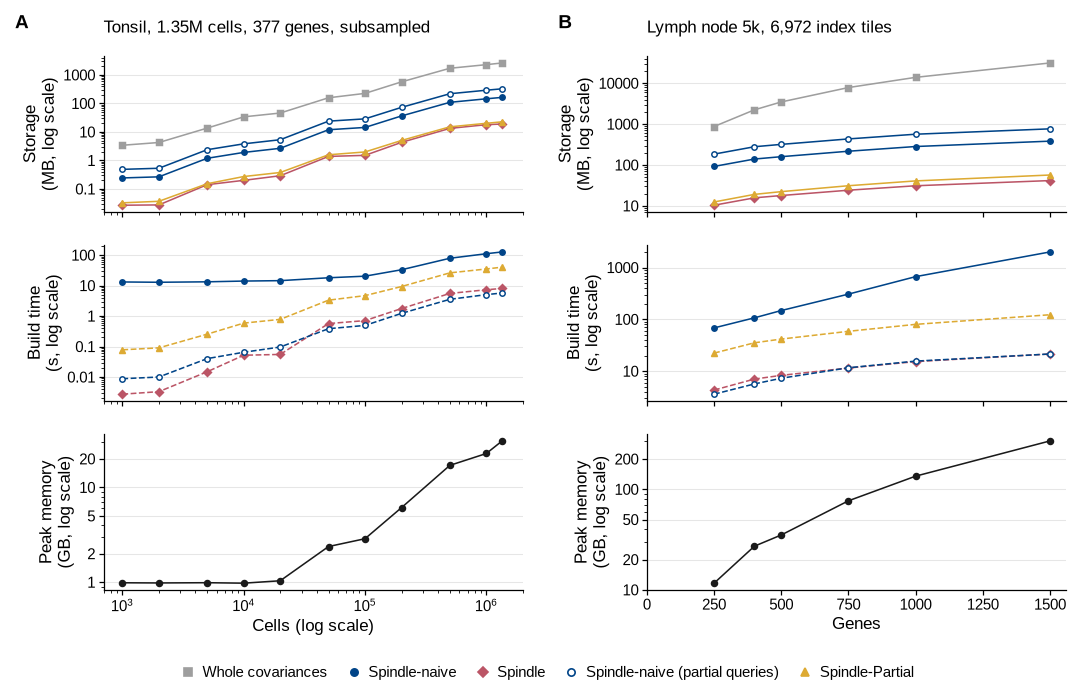

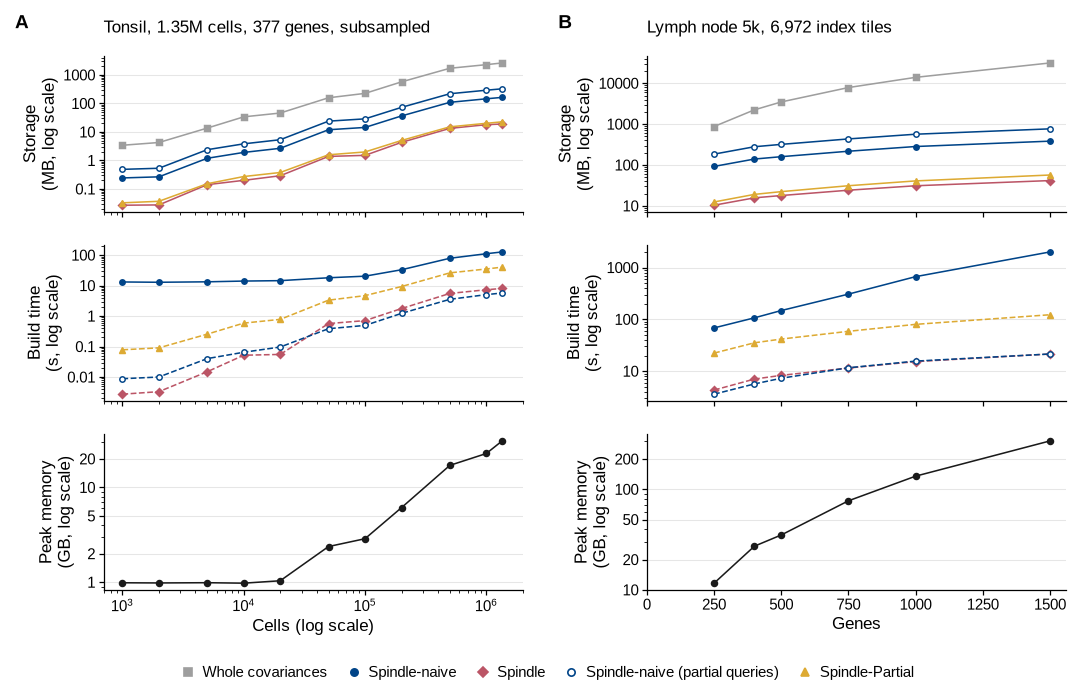

In [4]:
Y_LEG = 3.0 + H2 + 1.5
page = ps.page(180, Y_LEG + 6.0)
panel_ladder(ps.place(page, "A", 0, 3.0, W_D, H2, dy=-0.5), "cells")
panel_ladder(ps.place(page, "B", 92, 3.0, W_D, H2, dy=-0.5), "genes")
panel_legend(ps.place(page, None, 1, Y_LEG, 178, 5))
ps.save_figure(page, FIG)
page